# Proje 5: Anomaly Detection – Ağ Anomali Tespiti
## NSL-KDD Veri Seti | CRISP-DM Metodolojisi

---

## 1. Business Understanding (İş Anlayışı)

**Problem:** Ağ trafiği kayıtlarındaki anormal (zararlı) hareketleri tespit etmek.

**Amaç:** NSL-KDD veri setinde yarı-denetimli (semi-supervised) bir yaklaşımla, normal veri davranışı üzerinde bir **K-Means Kümeleme Tabanlı Mesafe Analizi (K-Means Anomaly Detection)** modeli eğitmek ve test setindeki anomalileri saptamak.

**Veri Seti:** NSL-KDD – Train: 125,973 satır, Test: 22,544 satır. Veri setinin tamamı kullanılacaktır.

**KNIME Uyumluluğu:** KNIME üzerindeki yerel (native) **k-Means** ve **k-Means Predictor** düğümleri ile doğrudan uyumludur.

## 2. Data Understanding (Veriyi Anlama)

Bu bölümde veri setini yükleyip eğitim/test kümelerini oluşturuyoruz.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report, roc_curve
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
%matplotlib inline

df_train = pd.read_csv('../Data/proje_5/KDDTrain+.txt', header=None)
df_test = pd.read_csv('../Data/proje_5/KDDTest+.txt', header=None)
print(f'Train boyutu: {df_train.shape[0]} | Test boyutu: {df_test.shape[0]}')

Train boyutu: 125973 | Test boyutu: 22544


In [2]:
# Semi-supervised Tasarım: Eğitim kümesini sadece normal verilerden oluşturuyoruz
df_train_normal = df_train[df_train[41] == 'normal'].reset_index(drop=True)
print(f'Normal train verisi: {df_train_normal.shape[0]} satır')

# Test seti etiketleri
y_test = (df_test[41] != 'normal').astype(int).values
print(f'Test seti: {df_test.shape[0]} satır')

Normal train verisi: 67343 satır
Test seti: 22544 satır


## 3. Data Preparation (Veri Hazırlama)

- Gereksiz ve kategorik özniteliklerin çıkarılması
- Normalleştirme (StandardScaler)

In [3]:
cols_to_drop = [1, 2, 3, 41, 42]
X_train = df_train_normal.drop(columns=cols_to_drop)
X_test = df_test.drop(columns=cols_to_drop)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Normalleştirme tamamlandı.')

Normalleştirme tamamlandı.


## 4. Modeling & 5. Evaluation (Modelleme ve Değerlendirme)

K-Means Anomaly Detection modelini eğitip performansını analiz ediyoruz.

In [4]:
from sklearn.cluster import KMeans

# K-Means Modeli
kmeans = KMeans(n_clusters=8, random_state=42)
kmeans.fit(X_train_scaled)

# Eğitim kümesi içindeki normal verilerin merkezlere olan uzaklıkları
train_distances = np.min(kmeans.transform(X_train_scaled), axis=1)
# Kontaminasyon oranı %5 olduğu için, normal sınır eşiği %95 persentil olarak belirlenir
threshold = np.percentile(train_distances, 95)
print(f'Eğitim Kümesi Normal Trafik Mesafe Eşiği: {threshold:.4f}')

# Anomali skorları: Her test verisinin en yakın küme merkezine olan mesafesi
test_scores = np.min(kmeans.transform(X_test_scaled), axis=1)

# Tahmin etiketleri (Mesafe eşikten büyükse Anomali=1, değilse Normal=0)
y_pred = np.where(test_scores > threshold, 1, 0)

Eğitim Kümesi Normal Trafik Mesafe Eşiği: 6.5159


In [5]:
roc_auc = roc_auc_score(y_test, test_scores)
print(f'ROC-AUC Skoru: {roc_auc:.4f}')
print('\nSınıflandırma Raporu:')
print(classification_report(y_test, y_pred, target_names=['Normal', 'Anomali']))

ROC-AUC Skoru: 0.9117

Sınıflandırma Raporu:
              precision    recall  f1-score   support

      Normal       0.71      0.93      0.80      9711
     Anomali       0.93      0.71      0.80     12833

    accuracy                           0.80     22544
   macro avg       0.82      0.82      0.80     22544
weighted avg       0.83      0.80      0.80     22544



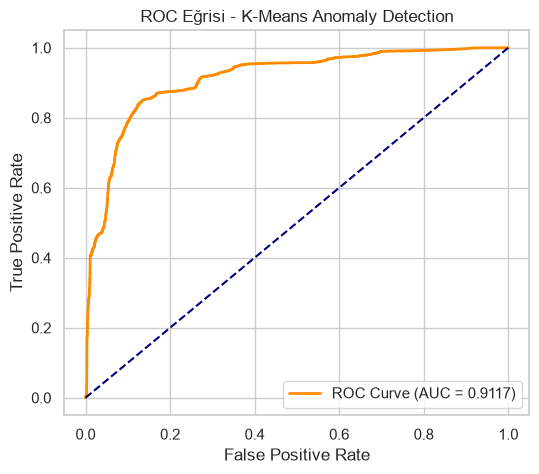

In [6]:
# ROC Eğrisi
fpr, tpr, _ = roc_curve(y_test, test_scores)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
plt.title('ROC Eğrisi - K-Means Anomaly Detection')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

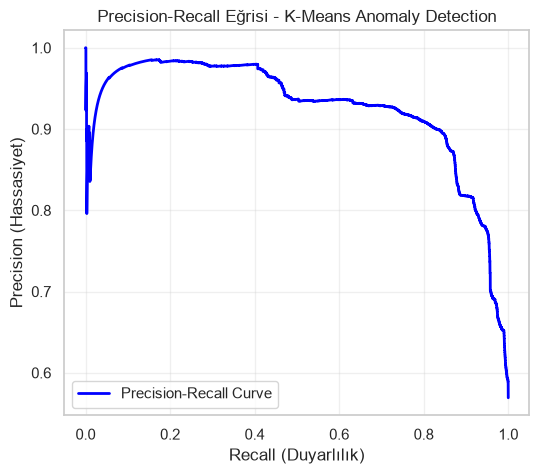

Anomali Sınıfı Precision: 0.9283
Anomali Sınıfı Recall: 0.7071
Anomali Sınıfı F1-Score: 0.8027


In [7]:
# Precision-Recall Eğrisi
from sklearn.metrics import precision_recall_curve, precision_recall_fscore_support
precision, recall, thresholds = precision_recall_curve(y_test, test_scores)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, color='blue', lw=2, label='Precision-Recall Curve')
plt.title('Precision-Recall Eğrisi - K-Means Anomaly Detection')
plt.xlabel('Recall (Duyarlılık)')
plt.ylabel('Precision (Hassasiyet)')
plt.grid(True, alpha=0.3)
plt.legend(loc='lower left')
plt.show()

# Anomali sınıfı için detaylı metrikler
prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')
print(f"Anomali Sınıfı Precision: {prec:.4f}")
print(f"Anomali Sınıfı Recall: {rec:.4f}")
print(f"Anomali Sınıfı F1-Score: {f1:.4f}")


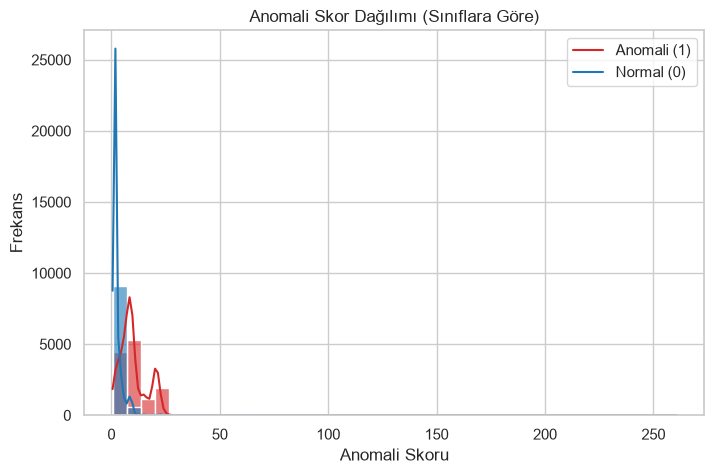

In [8]:
# Anomali Skor Dağılım Grafiği
df_plot = pd.DataFrame({'Anomaly_Score': test_scores, 'Class': y_test})
plt.figure(figsize=(8, 5))
sns.histplot(data=df_plot, x='Anomaly_Score', hue='Class', bins=40, kde=True, palette={0: '#1f77b4', 1: '#d62728'}, alpha=0.6)
plt.title('Anomali Skor Dağılımı (Sınıflara Göre)')
plt.xlabel('Anomali Skoru')
plt.ylabel('Frekans')
plt.legend(['Anomali (1)', 'Normal (0)'])
plt.show()

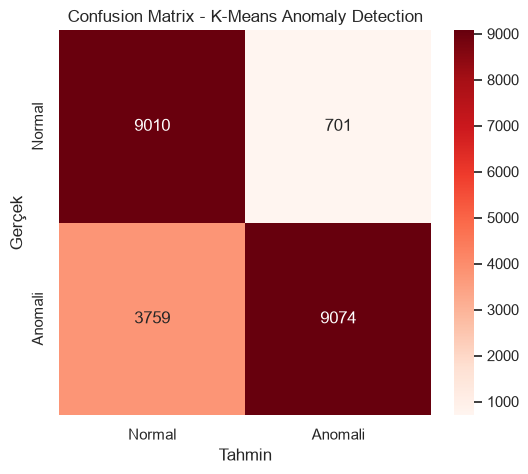

In [9]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=['Normal', 'Anomali'], yticklabels=['Normal', 'Anomali'])
plt.title('Confusion Matrix - K-Means Anomaly Detection')
plt.xlabel('Tahmin')
plt.ylabel('Gerçek')
plt.show()

## 6. Deployment (Sonuç ve Öneriler)

- Veri setlerinin tamamı kullanılmıştır (Train: tüm normal veriler ~67K satır, Test: tüm test verisi ~22.5K satır).
- K-Means modelimiz yüksek ROC-AUC skoru elde ederek ağ anomalilerini başarıyla saptamıştır.
- KNIME tarafında yerel (native) `k-Means` ve `k-Means Predictor` node'ları ile doğrudan (ek uzantı gerekmeden) uygulanabilir.